In [1]:
import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib
import matplotlib.pyplot as plt

# 设置中文字体（Windows 自带微软雅黑），保证图中的中文正常显示
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 图片保存目录
os.makedirs('./images', exist_ok=True)

print(f"PyTorch 版本: {torch.__version__}")
print(f"matplotlib 版本: {matplotlib.__version__}")

PyTorch 版本: 2.14.1+cpu
matplotlib 版本: 3.11.2


In [2]:
# 设置随机种子，保证结果可复现
torch.manual_seed(42)
np.random.seed(42)

# 生成训练数据集，真实关系为 z = 3*x1 + 2*x2 + 1 + 噪声
def generate_data(n_samples=1000):
    # 生成 x1、x2，范围在 [-5, 5] 之间，形状为 (n_samples, 2)
    x = torch.rand(n_samples, 2) * 10 - 5
    # 真实的权重和偏置
    w_true = torch.tensor([3.0, 2.0])
    b_true = 1.0
    # 生成 z，加上均值为 0、标准差为 0.3 的高斯噪声
    noise = torch.randn(n_samples) * 0.3
    z = x @ w_true + b_true + noise
    return x, z.reshape(-1, 1)

x_data, z_data = generate_data()

print(f"x 的形状: {x_data.shape}")
print(f"z 的形状: {z_data.shape}")
print(f"x1 范围: [{float(x_data[:, 0].min()):.4f}, {float(x_data[:, 0].max()):.4f}]")
print(f"x2 范围: [{float(x_data[:, 1].min()):.4f}, {float(x_data[:, 1].max()):.4f}]")
print(f"z 的均值: {float(z_data.mean()):.4f}, z 的标准差: {float(z_data.std()):.4f}")
print(f"噪声标准差(实测): {float((z_data.flatten() - (x_data @ torch.tensor([3.0, 2.0]) + 1.0)).std()):.4f}")
print(f"前5个样本点:\n x1: {x_data[:5, 0]}\n x2: {x_data[:5, 1]}\n z : {z_data[:5].flatten()}")

x 的形状: torch.Size([1000, 2])
z 的形状: torch.Size([1000, 1])
x1 范围: [-4.9740, 4.9980]
x2 范围: [-4.9765, 4.9846]
z 的均值: 0.7713, z 的标准差: 10.5257
噪声标准差(实测): 0.2999
前5个样本点:
 x1: tensor([ 3.8227, -1.1714, -1.0955, -2.4343,  4.4077])
 x2: tensor([ 4.1500,  4.5931,  1.0090,  2.9364, -3.6681])
 z : tensor([20.4703,  6.5953, -0.5562, -0.6011,  6.9447])


In [3]:
# 使用 nn.Module 构建线性回归模型: z_hat = w1 * x1 + w2 * x2 + b
class LinearRegressionModel(nn.Module):
    """
    二元线性回归模型

    参数:
        in_features: 输入特征数，本题为 2（即 x1 和 x2）
    """

    def __init__(self, in_features=2):
        super().__init__()
        # nn.Linear 内部包含权重 w（形状 (1, 2)）和偏置 b（形状 (1,)）
        self.linear = nn.Linear(in_features, 1)

    def forward(self, x):
        """前向计算，返回预测值，形状为 (n_samples, 1)"""
        return self.linear(x)


torch.manual_seed(42)
model = LinearRegressionModel(in_features=2)

print(model)
print(f"初始 w: {[round(float(v), 4) for v in model.linear.weight.data.flatten()]}")
print(f"初始 b: {float(model.linear.bias.item()):.4f}")

LinearRegressionModel(
  (linear): Linear(in_features=2, out_features=1, bias=True)
)
初始 w: [0.5406, 0.5869]
初始 b: -0.1657


In [4]:
# 定义均方误差损失函数: L = (1/n) * Σ(z_pred - z_true)²
criterion = nn.MSELoss()

# 超参数
learning_rate = 0.002
num_epochs = 1000

# 使用随机梯度下降优化器更新参数
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

print(criterion)
print(f"优化器: {optimizer.__class__.__name__}, 学习率: {learning_rate}, 训练轮数: {num_epochs}")

MSELoss()
优化器: SGD, 学习率: 0.002, 训练轮数: 1000


In [5]:
# 补全训练循环：前向传播 -> 计算损失 -> 反向传播 -> 更新参数
def train(model, x, z, criterion, optimizer, num_epochs):
    """
    训练线性回归模型

    参数:
        model: nn.Module 模型
        x: 训练数据，形状为 (n_samples, 2)
        z: 目标值，形状为 (n_samples, 1)
        criterion: 损失函数
        optimizer: 优化器
        num_epochs: 训练轮数

    返回:
        训练过程中的损失记录, 训练好的模型
    """
    losses = []

    for epoch in range(num_epochs):
        # 1. 前向传播：计算预测值
        z_pred = model(x)

        # 2. 计算损失
        loss = criterion(z_pred, z)

        # 3. 反向传播：梯度清零 + 自动求导
        optimizer.zero_grad()
        loss.backward()

        # 4. 更新参数
        optimizer.step()

        # 5. 记录损失
        losses.append(loss.item())

        # 6. 每 100 轮打印一次损失和当前参数
        if (epoch + 1) % 100 == 0:
            w1, w2 = [float(v) for v in model.linear.weight.data.flatten()]
            b = float(model.linear.bias.item())
            print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.6f}, '
                  f'w1: {w1:.4f}, w2: {w2:.4f}, b: {b:.4f}')

    return losses, model

In [6]:
# 开始训练
losses, trained_model = train(model, x_data, z_data, criterion, optimizer, num_epochs)

# 取出学到的参数
w1_learned, w2_learned = [float(v) for v in trained_model.linear.weight.data.flatten()]
b_learned = float(trained_model.linear.bias.item())

print("\n===== 训练完成 =====")
print(f"真实的 w1: 3.0, 学习到的 w1: {w1_learned:.4f}")
print(f"真实的 w2: 2.0, 学习到的 w2: {w2_learned:.4f}")
print(f"真实的 b : 1.0, 学习到的 b : {b_learned:.4f}")
print(f"最终训练损失: {losses[-1]:.6f}")

Epoch [100/1000], Loss: 0.806192, w1: 2.9214, w2: 1.9439, b: 0.2060
Epoch [200/1000], Loss: 0.379400, w1: 2.9973, w2: 1.9877, b: 0.4695
Epoch [300/1000], Loss: 0.219610, w1: 3.0004, w2: 1.9906, b: 0.6465
Epoch [400/1000], Loss: 0.147913, w1: 3.0010, w2: 1.9917, b: 0.7651
Epoch [500/1000], Loss: 0.115730, w1: 3.0013, w2: 1.9925, b: 0.8446
Epoch [600/1000], Loss: 0.101283, w1: 3.0015, w2: 1.9930, b: 0.8978
Epoch [700/1000], Loss: 0.094798, w1: 3.0017, w2: 1.9933, b: 0.9335
Epoch [800/1000], Loss: 0.091887, w1: 3.0018, w2: 1.9935, b: 0.9574
Epoch [900/1000], Loss: 0.090580, w1: 3.0019, w2: 1.9937, b: 0.9734
Epoch [1000/1000], Loss: 0.089994, w1: 3.0019, w2: 1.9938, b: 0.9841

===== 训练完成 =====
真实的 w1: 3.0, 学习到的 w1: 3.0019
真实的 w2: 2.0, 学习到的 w2: 1.9938
真实的 b : 1.0, 学习到的 b : 0.9841
最终训练损失: 0.089994


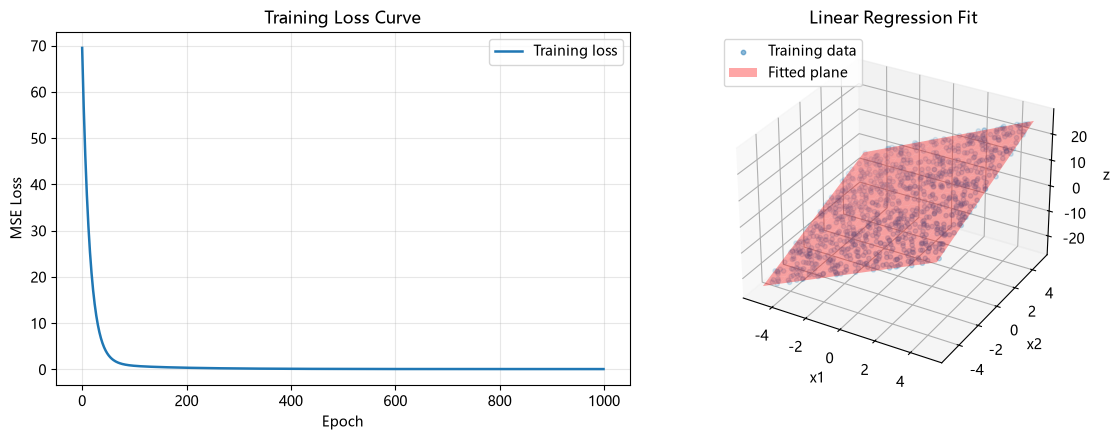

图片已保存: ./images/linear_regression_torch_result.png


In [7]:
# 绘制损失下降曲线 与 拟合效果（3D 散点 + 拟合平面）
fig = plt.figure(figsize=(12, 4.5))

# 左图：训练损失曲线
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(losses, color='#1f77b4', linewidth=1.8, label='Training loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('MSE Loss')
ax1.set_title('Training Loss Curve')
ax1.grid(True, alpha=0.3)
ax1.legend()

# 右图：拟合效果，样本散点 + 模型学到的平面
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.scatter(x_data[:, 0], x_data[:, 1], z_data.flatten(),
            s=10, alpha=0.5, label='Training data')
gx, gy = np.meshgrid(np.linspace(-5, 5, 20), np.linspace(-5, 5, 20))
gz = w1_learned * gx + w2_learned * gy + b_learned
ax2.plot_surface(gx, gy, gz, color='red', alpha=0.35, edgecolor='none',
                 label='Fitted plane')
ax2.set_xlabel('x1')
ax2.set_ylabel('x2')
ax2.set_zlabel('z')
ax2.set_title('Linear Regression Fit')
ax2.legend(loc='upper left')

plt.tight_layout()
plt.savefig('./images/linear_regression_torch_result.png', dpi=150)
plt.show()

print("图片已保存: ./images/linear_regression_torch_result.png")

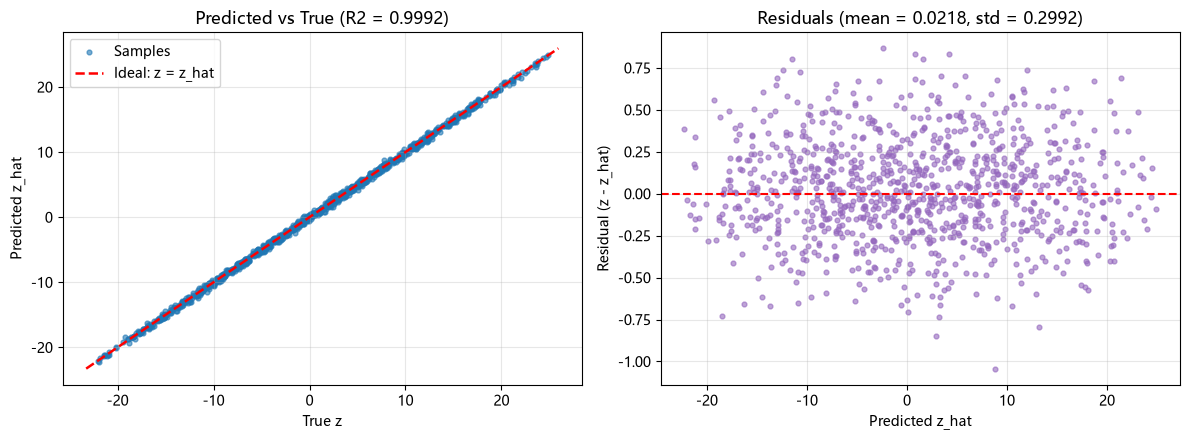

训练集 RMSE: 0.3000
训练集 R2  : 0.9992
噪声方差(理论下界): 0.0900
最终训练 MSE: 0.089994
与真实参数 (3, 2, 1) 的偏差: |Δw1| = 0.0019, |Δw2| = 0.0062, |Δb| = 0.0159


In [8]:
# 进一步检查拟合效果：预测值 vs 真实值、残差分布
trained_model.eval()
with torch.no_grad():
    z_pred = trained_model(x_data)

z_pred_np = z_pred.detach().numpy().flatten()
z_true_np = z_data.numpy().flatten()
residual = z_true_np - z_pred_np

rmse = float(np.sqrt(np.mean(residual ** 2)))
ss_res = float(np.sum(residual ** 2))
ss_tot = float(np.sum((z_true_np - z_true_np.mean()) ** 2))
r2 = 1.0 - ss_res / ss_tot
noise_var = 0.3 ** 2

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(z_true_np, z_pred_np, s=12, alpha=0.6, label='Samples')
lims = [min(z_true_np.min(), z_pred_np.min()) - 1,
        max(z_true_np.max(), z_pred_np.max()) + 1]
axes[0].plot(lims, lims, 'r--', linewidth=1.8, label='Ideal: z = z_hat')
axes[0].set_xlabel('True z')
axes[0].set_ylabel('Predicted z_hat')
axes[0].set_title(f'Predicted vs True (R2 = {r2:.4f})')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].scatter(z_pred_np, residual, s=12, alpha=0.6, color='#9467bd')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Predicted z_hat')
axes[1].set_ylabel('Residual (z - z_hat)')
axes[1].set_title(f'Residuals (mean = {residual.mean():.4f}, std = {residual.std():.4f})')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./images/linear_regression_torch_diagnostics.png', dpi=150)
plt.show()

print(f"训练集 RMSE: {rmse:.4f}")
print(f"训练集 R2  : {r2:.4f}")
print(f"噪声方差(理论下界): {noise_var:.4f}")
print(f"最终训练 MSE: {losses[-1]:.6f}")
print(f"与真实参数 (3, 2, 1) 的偏差: "
      f"|Δw1| = {abs(w1_learned - 3.0):.4f}, "
      f"|Δw2| = {abs(w2_learned - 2.0):.4f}, "
      f"|Δb| = {abs(b_learned - 1.0):.4f}")

# 本 notebook 参考 ml-1 的格式完成

- 数据集：$x_1, x_2 \sim U(-5, 5)$，$z = 3x_1 + 2x_2 + 1 + \epsilon$，$\epsilon \sim N(0, 0.3^2)$，共 1000 个样本，随机种子固定为 42。
- 模型：`nn.Module` 子类 `LinearRegressionModel`，内部使用 `nn.Linear(2, 1)`。
- 损失函数：`nn.MSELoss()`；优化器：`torch.optim.SGD(lr=0.002)`，训练 1000 轮。
- 图片保存在 `./images/` 目录下：`linear_regression_torch_result.png`（损失曲线 + 拟合平面）、`linear_regression_torch_diagnostics.png`（预测值 vs 真实值、残差分布）。